# Lab 1 (Parcial 2) — Del texto a secuencias: tokenización, vocabulario y ley de Zipf

## Objetivos

Antes de entrenar un modelo de lenguaje hay que convertir el texto en **secuencias de números**: se carga el texto, se divide en **tokens** (caracteres o palabras), se construye un **vocabulario** que asigna un índice a cada token y se traduce el texto a índices. Con esos tokens se pueden estudiar las **estadísticas del lenguaje**: qué palabras son más frecuentes y cómo decae su frecuencia, que sigue aproximadamente la **ley de Zipf**, $n_i\propto 1/i^{\alpha}$.

Tareas (cuaderno y diapositivas del Lab 1):

1. Ejecutar el cuaderno proporcionado (`L1NB.ipynb`) y entender sus órdenes: descarga de *The Time Machine*, tokenización en caracteres, vocabulario, frecuencias de palabras y gráficas log-log de unigramas, bigramas y trigramas.
2. Ajustar por regresión lineal el **exponente de Zipf** para unigramas, bigramas y trigramas de *The Time Machine*, eliminando los primeros valores (frecuencias muy altas) y los últimos (frecuencia 1), y medir la bondad del ajuste ($R^2$ y MSE).
3. Repetir el análisis con el texto en español *Juvenilia*.
4. Comparar ambos idiomas (palabras y caracteres más frecuentes, exponentes) y con lo descrito en la literatura para corpus grandes, teniendo en cuenta que los corpus son limitados.
5. Revisar las codificaciones **one-hot** y **TF-IDF** y la métrica de **perplejidad**.

## 1. Preparación del entorno

En Colab: `!pip install d2l==1.0.0a0 Unidecode`. En local se usa el entorno de `Parcial-2/requirements.txt`. El libro *The Time Machine* se descarga con `d2l.download` (y se guarda en `Lab-1/data/`); *Juvenilia* se lee del archivo proporcionado.

In [1]:
%matplotlib inline
# !pip install d2l==1.0.0a0 Unidecode     # descomentar en Colab
import collections
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F
from unidecode import unidecode
from d2l import torch as d2l

LAB_DIR = None
for candidato in (Path.cwd(), Path.cwd() / 'Lab-1',
                  Path.cwd() / 'Parcial-2' / 'Lab-1-Working-with-sequences' / 'Lab-1'):
    if (candidato / 'Juvenilia.txt').exists():
        LAB_DIR = candidato
        break
if LAB_DIR is None:
    raise FileNotFoundError('No se encuentra Juvenilia.txt')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.max_colwidth', 80)
print('PyTorch', torch.__version__, '| datos en', LAB_DIR.name)

PyTorch 2.15.0 | datos en Lab-1


# Parte A — Cuaderno base comentado

## 2. El conjunto de datos: *The Time Machine*

La clase `TimeMachine` hereda de `d2l.DataModule`. `_download` descarga el libro de H. G. Wells (algo más de 30 000 palabras) desde el servidor de d2l, comprueba su integridad con un hash SHA-1 y lo devuelve como **una sola cadena de texto**.

In [2]:
class TimeMachine(d2l.DataModule):  #@save
    """The Time Machine dataset."""
    def _download(self):
        fname = d2l.download(d2l.DATA_URL + 'timemachine.txt', self.root,
                             '090b5e7e70c295757f55df93cb0a180b9691891a')
        with open(fname) as f:
            return f.read()


data = TimeMachine(root=str(LAB_DIR / 'data'))
raw_text = data._download()
print(f'{len(raw_text):,} caracteres en bruto')
raw_text[:60]

178,979 caracteres en bruto


'The Time Machine, by H. G. Wells [1898]\n\n\n\n\nI\n\n\nThe Time Tra'

## 3. Preprocesado y tokenización en caracteres

Por simplicidad se ignoran la puntuación y las mayúsculas: la expresión regular `[^A-Za-z]+` sustituye **cada racha de caracteres que no son letras** (signos, dígitos, saltos de línea) por un espacio, y `lower()` pasa todo a minúsculas. Después, `_tokenize` convierte la cadena en una **lista de caracteres**: cada carácter es un token, es decir, un paso temporal de la secuencia.

In [3]:
@d2l.add_to_class(TimeMachine)  #@save
def _preprocess(self, text):
    return re.sub('[^A-Za-z]+', ' ', text).lower()


@d2l.add_to_class(TimeMachine)  #@save
def _tokenize(self, text):
    return list(text)


text = data._preprocess(raw_text)
tokens = data._tokenize(text)
print(repr(text[:60]))
print(','.join(tokens[:30]))

'the time machine by h g wells i the time traveller for so it'
t,h,e, ,t,i,m,e, ,m,a,c,h,i,n,e, ,b,y, ,h, ,g, ,w,e,l,l,s, 


## 4. Vocabulario: de tokens a índices

Los modelos necesitan números, no cadenas. La clase `Vocab`:

1. Aplana la lista si es de listas y **cuenta** cuántas veces aparece cada token (`collections.Counter`); `token_freqs` guarda los pares (token, frecuencia) ordenados de más a menos frecuente.
2. Construye la lista `idx_to_token` con los tokens únicos **ordenados alfabéticamente**, más el token especial `<unk>` y los reservados. Los tokens con frecuencia menor que `min_freq` se descartan.
3. Crea el diccionario inverso `token_to_idx`.
4. `vocab[token]` devuelve el índice (o el de `<unk>` si el token no se ha visto nunca) y `to_tokens` hace la traducción inversa.

> En esta versión los índices siguen el **orden alfabético** (con `sorted`), no el de frecuencia: el espacio `' '` tiene índice 0 o 1 porque es el primer carácter en el orden ASCII. La tabla de frecuencias, en cambio, sí está ordenada por frecuencia.

In [4]:
class Vocab:  #@save
    """Vocabulary for text."""
    def __init__(self, tokens=[], min_freq=0, reserved_tokens=[]):
        # Flatten a 2D list if needed
        if tokens and isinstance(tokens[0], list):
            tokens = [token for line in tokens for token in line]
        # Count token frequencies
        counter = collections.Counter(tokens)
        self.token_freqs = sorted(counter.items(), key=lambda x: x[1],
                                  reverse=True)
        # The list of unique tokens
        self.idx_to_token = list(sorted(set(['<unk>'] + reserved_tokens + [
            token for token, freq in self.token_freqs if freq >= min_freq])))
        self.token_to_idx = {token: idx
                             for idx, token in enumerate(self.idx_to_token)}

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]

    def to_tokens(self, indices):
        if hasattr(indices, '__len__') and len(indices) > 1:
            return [self.idx_to_token[int(index)] for index in indices]
        return self.idx_to_token[indices]

    @property
    def unk(self):  # Index for the unknown token
        return self.token_to_idx['<unk>']


vocab = Vocab(tokens)
indices = vocab[tokens[:10]]
print('indices:', indices)
print('words:', vocab.to_tokens(indices))
print('índice de un carácter nunca visto (ñ):', vocab['ñ'], '→', vocab.to_tokens(vocab['ñ']))

indices: [21, 9, 6, 0, 21, 10, 14, 6, 0, 14]
words: ['t', 'h', 'e', ' ', 't', 'i', 'm', 'e', ' ', 'm']
índice de un carácter nunca visto (ñ): 1 → <unk>


## 5. Todo junto: `build`

`build` encadena preprocesado → tokenización → vocabulario → índices y devuelve `corpus` (la lista de índices de **todo el libro**, una sola lista porque las líneas del libro no son frases completas) y `vocab`.

In [5]:
@d2l.add_to_class(TimeMachine)  #@save
def build(self, raw_text, vocab=None):
    tokens = self._tokenize(self._preprocess(raw_text))
    if vocab is None: vocab = Vocab(tokens)
    corpus = [vocab[token] for token in tokens]
    return corpus, vocab


corpus, vocab = data.build(raw_text)
print('longitud del corpus:', len(corpus), '| tamaño del vocabulario:', len(vocab))
tabla_chars_en = pd.DataFrame(vocab.token_freqs, columns=['carácter', 'frecuencia'])
tabla_chars_en['%'] = (100 * tabla_chars_en.frecuencia / len(corpus)).round(2)
tabla_chars_en.head(10).T

longitud del corpus: 173428 | tamaño del vocabulario: 28


,0,1,2,3,4,5,6,7,8,9
carácter,,e,t,a,i,n,o,s,h,r
frecuencia,32775,17838,13515,11704,10138,9917,9758,8486,8257,7674
%,18.9,10.29,7.79,6.75,5.85,5.72,5.63,4.89,4.76,4.42


El vocabulario tiene **28 elementos**: 26 letras, el espacio y `<unk>` (que nunca aparece en este texto). El corpus tiene 173 428 caracteres (las diapositivas indican 170 580, probablemente con otra versión del archivo o del preprocesado; la diferencia no afecta a las conclusiones). El carácter más frecuente es el espacio y la letra más frecuente, la «e».

## 6. Estadísticas de palabras y ley de Zipf

Ahora los tokens son **palabras** (`text.split()` separa por espacios). Las más frecuentes son *stop words* (artículos, pronombres, preposiciones): no son descriptivas, pero tienen función sintáctica y los modelos neuronales modernos no las eliminan. La frecuencia cae muy rápido: la décima palabra aparece menos de 1/5 de veces que la primera.

In [6]:
words = text.split()
vocab = Vocab(words)
print(f'{len(words):,} palabras, {len(vocab):,} entradas en el vocabulario (incluido <unk>)')
vocab.token_freqs[:10]

32,775 palabras, 4,580 entradas en el vocabulario (incluido <unk>)


[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

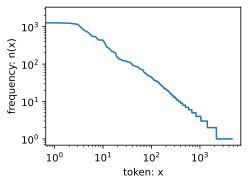

In [7]:
freqs = [freq for token, freq in vocab.token_freqs]
d2l.plot(freqs, xlabel='token: x', ylabel='frequency: n(x)',
         xscale='log', yscale='log')

Salvo las primeras palabras, la curva es casi una **recta en escala log-log**. Es la **ley de Zipf**: la frecuencia $n_i$ de la $i$-ésima palabra más frecuente cumple

$$n_i\propto\frac{1}{i^{\alpha}}\quad\Longleftrightarrow\quad\log n_i=-\alpha\log i+c,$$

así que el exponente $\alpha$ es la **pendiente cambiada de signo** de esa recta. Consecuencia: si modelamos palabras contando, sobrestimaremos mucho la frecuencia de la cola (palabras raras). ¿Pasa lo mismo con pares (**bigramas**) y tríos (**trigramas**) de palabras consecutivas?

In [8]:
bigram_tokens = ['--'.join(pair) for pair in zip(words[:-1], words[1:])]
bigram_vocab = Vocab(bigram_tokens)
bigram_vocab.token_freqs[:10]

[('of--the', 309),
 ('in--the', 169),
 ('i--had', 130),
 ('i--was', 112),
 ('and--the', 109),
 ('the--time', 102),
 ('it--was', 99),
 ('to--the', 85),
 ('as--i', 78),
 ('of--a', 73)]

In [9]:
trigram_tokens = ['--'.join(triple) for triple in zip(
    words[:-2], words[1:-1], words[2:])]
trigram_vocab = Vocab(trigram_tokens)
trigram_vocab.token_freqs[:10]

[('the--time--traveller', 59),
 ('the--time--machine', 30),
 ('the--medical--man', 24),
 ('it--seemed--to', 16),
 ('it--was--a', 15),
 ('here--and--there', 15),
 ('seemed--to--me', 14),
 ('i--did--not', 14),
 ('i--saw--the', 13),
 ('i--began--to', 13)]

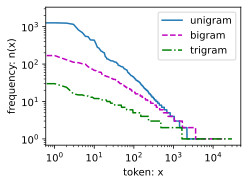

In [10]:
bigram_freqs = [freq for token, freq in bigram_vocab.token_freqs]
trigram_freqs = [freq for token, freq in trigram_vocab.token_freqs]
d2l.plot([freqs, bigram_freqs, trigram_freqs], xlabel='token: x',
         ylabel='frequency: n(x)', xscale='log', yscale='log',
         legend=['unigram', 'bigram', 'trigram'])

De los diez bigramas más frecuentes, nueve están formados solo por *stop words*; solo «the time» tiene que ver con el libro. Entre los trigramas ya aparecen expresiones propias de la novela («the time traveller», «the time machine»). Las tres curvas siguen una ley de potencias, **con exponente menor** (pendiente más suave) para bigramas y trigramas, y muchos $n$-gramas aparecen **una sola vez**: los métodos basados en contar $n$-gramas no escalan, lo que motiva los modelos de aprendizaje profundo.

# Parte B — Ejercicios

## 7. Herramientas comunes

* `ngramas(palabras, n)`: $n$-gramas de palabras consecutivas unidos con `--`, igual que en el cuaderno base.
* `ajustar_zipf(freqs, saltar, min_freq)`: regresión lineal por mínimos cuadrados de $\log_{10}n_i$ frente a $\log_{10}i$ usando solo los rangos $i>$`saltar` (se eliminan las primeras palabras, de frecuencia muy alta) y con frecuencia $\ge$`min_freq` (con `min_freq=2` se elimina la cola de frecuencia 1, como pide el enunciado). Devuelve $\alpha$ (= −pendiente), la ordenada $c$ y la bondad del ajuste en el espacio log-log:

$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2},\qquad \text{MSE}=\frac1m\sum(y_i-\hat y_i)^2,\qquad y_i=\log_{10}n_i.$$

El exponente no depende de la base del logaritmo (la pendiente es la misma en $\log_{10}$ que en $\ln$); el MSE sí, y está en unidades de $\log_{10}$ al cuadrado.

In [11]:
def ngramas(palabras, n):
    return ['--'.join(g) for g in zip(*[palabras[i:] for i in range(n)])]


def frecuencias(tokens):
    return [freq for _, freq in Vocab(tokens).token_freqs]


def ajustar_zipf(freqs, saltar=10, min_freq=2):
    """Ajuste log10(n_i) = -alpha·log10(i) + c con los rangos i > saltar y frecuencia >= min_freq."""
    f = np.asarray(freqs, dtype=float)
    rango = np.arange(1, len(f) + 1)
    usar = (rango > saltar) & (f >= min_freq)
    x, y = np.log10(rango[usar]), np.log10(f[usar])
    pendiente, c = np.polyfit(x, y, 1)
    residuos = y - (pendiente * x + c)
    return {'alpha': -pendiente, 'c': c,
            'R2': 1 - (residuos ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            'MSE': (residuos ** 2).mean(), 'puntos': int(usar.sum()),
            'rango_min': int(rango[usar].min()), 'rango_max': int(rango[usar].max())}


def analizar(palabras, saltar=10, min_freq=2):
    """Frecuencias y ajuste de Zipf para unigramas, bigramas y trigramas."""
    res = {}
    for n, nombre in ((1, 'unigramas'), (2, 'bigramas'), (3, 'trigramas')):
        freqs = frecuencias(ngramas(palabras, n))
        res[nombre] = {'freqs': freqs, 'tipos': len(freqs),
                       'hapax': sum(f == 1 for f in freqs), **ajustar_zipf(freqs, saltar, min_freq)}
    return res


def tabla_ajustes(res):
    return pd.DataFrame({k: {'tipos distintos': v['tipos'], '% con frecuencia 1': 100 * v['hapax'] / v['tipos'],
                             'puntos ajustados': v['puntos'], 'rangos': f"{v['rango_min']}–{v['rango_max']}",
                             'α': v['alpha'], 'c': v['c'], 'R²': v['R2'], 'MSE (log10²)': v['MSE']}
                         for k, v in res.items()}).T


def grafica_zipf(res, titulo, ax):
    colores = {'unigramas': 'tab:blue', 'bigramas': 'tab:orange', 'trigramas': 'tab:green'}
    for nombre, v in res.items():
        rango = np.arange(1, len(v['freqs']) + 1)
        ax.loglog(rango, v['freqs'], color=colores[nombre], lw=1.2, label=f"{nombre} (α = {v['alpha']:.2f})")
        xr = np.array([v['rango_min'], v['rango_max']])
        ax.loglog(xr, 10 ** v['c'] * xr ** (-v['alpha']), color='k', ls='--', lw=1)
    ax.set(xlabel='rango i', ylabel='frecuencia n(i)', title=titulo)
    ax.legend(fontsize=8)

## 8. Ejercicio 2 — Exponente de Zipf en *The Time Machine*

Cortes elegidos: se descartan los **10 primeros rangos** (las *stop words* más frecuentes, que se apartan de la recta) y los $n$-gramas con **frecuencia 1** (la cola, que forma una larga meseta horizontal: miles de rangos con la misma frecuencia, que no siguen una recta y dominarían el ajuste).

In [12]:
res_en = analizar(words)
tabla_ajustes(res_en).round(4)

,tipos distintos,% con frecuencia 1,puntos ajustados,rangos,α,c,R²,MSE (log10²)
unigramas,4579,52.347674,2172,11–2182,1.038922,3.685719,0.989915,0.001787
bigramas,20234,82.163685,3599,11–3609,0.652131,2.528564,0.965265,0.002598
trigramas,29882,94.541865,1621,11–1631,0.378368,1.443613,0.889186,0.002806


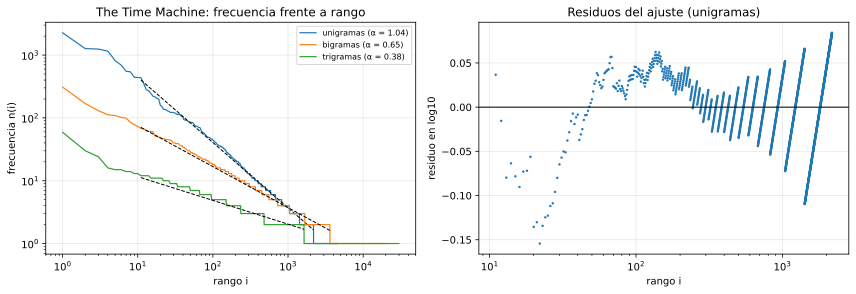

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
grafica_zipf(res_en, 'The Time Machine: frecuencia frente a rango', ax[0])
# Residuos del ajuste de unigramas
v = res_en['unigramas']
rango = np.arange(1, len(v['freqs']) + 1)
usar = (rango > 10) & (np.asarray(v['freqs']) >= 2)
residuo = np.log10(np.asarray(v['freqs'])[usar]) - (v['c'] - v['alpha'] * np.log10(rango[usar]))
ax[1].semilogx(rango[usar], residuo, '.', ms=3)
ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='rango i', ylabel='residuo en log10', title='Residuos del ajuste (unigramas)')
plt.tight_layout()
plt.show()

### ¿Cuánto depende α de los cortes?

Se repite el ajuste de unigramas, bigramas y trigramas con distintos números de rangos eliminados al principio (`saltar`) y distintos umbrales de frecuencia mínima (`min_freq`).

In [14]:
def sensibilidad(palabras):
    filas = []
    for n, nombre in ((1, 'unigramas'), (2, 'bigramas'), (3, 'trigramas')):
        freqs = frecuencias(ngramas(palabras, n))
        for saltar in (0, 10, 50):
            for min_freq in (1, 2, 3):
                r = ajustar_zipf(freqs, saltar, min_freq)
                filas.append({'n-grama': nombre, 'saltar': saltar, 'min_freq': min_freq,
                              'α': r['alpha'], 'R²': r['R2']})
    return pd.DataFrame(filas).pivot_table(index=['n-grama', 'saltar'], columns='min_freq', values=['α', 'R²'])


sens_en = sensibilidad(words)
sens_en.round(3)

R²                    α              
min_freq              1      2      3      1      2      3
n-grama   saltar                                          
bigramas  0       0.810  0.968  0.988  0.464  0.651  0.675
          10      0.805  0.965  0.987  0.460  0.652  0.683
          50      0.792  0.957  0.982  0.448  0.648  0.688
trigramas 0       0.529  0.905  0.963  0.164  0.384  0.430
          10      0.520  0.889  0.955  0.160  0.378  0.434
          50      0.497  0.843  0.910  0.149  0.357  0.433
unigramas 0       0.972  0.991  0.994  1.035  1.033  1.030
          10      0.970  0.990  0.994  1.038  1.039  1.039
          50      0.964  0.988  0.993  1.042  1.052  1.060

### Conclusiones del ejercicio 2

* **Los unigramas siguen muy bien la ley de Zipf**: $\alpha\approx1{,}04$ con $R^2\approx0{,}99$. Es el valor clásico, $\alpha\approx1$: la palabra de rango $i$ aparece aproximadamente $1/i$ veces lo que la más frecuente.
* **Bigramas y trigramas también siguen una ley de potencias, pero con exponente menor**: $\alpha\approx0{,}65$ y $\approx0{,}38$. Las curvas son más planas porque hay muchísimas más combinaciones distintas (20 234 bigramas y 29 882 trigramas frente a 4 579 palabras) y la frecuencia se reparte entre ellas.
* **El ajuste empeora con $n$** ($R^2$: 0,99 → 0,97 → 0,89): con trigramas el 95 % aparecen una sola vez y, tras quitar la cola, quedan pocos puntos y una curva escalonada (frecuencias 2, 3, 4… repetidas en muchos rangos).
* **Los cortes importan.** Incluir los $n$-gramas de frecuencia 1 (`min_freq=1`) añade una meseta horizontal muy larga que aplana la recta y baja α, sobre todo en bigramas y trigramas. Con `min_freq` 2 o 3 y `saltar` entre 0 y 50 el exponente de unigramas apenas cambia: el resultado es robusto para unigramas y algo menos para trigramas.
* El gráfico de residuos muestra lo esperado: pequeñas desviaciones sistemáticas (la ley de Zipf es una aproximación) y escalones en la cola por la naturaleza discreta de las frecuencias.

## 9. Ejercicio 3 — El mismo análisis con *Juvenilia* (español)

`Juvenilia.txt` es una edición del volumen de Miguel Cané que incluye un prólogo biográfico, *Juvenilia* (1882) y *Prosa ligera*. Se usa el archivo completo tal como se proporciona.

**Preprocesado.** El regex del cuaderno, `[^A-Za-z]+`, **rompería las palabras con tilde o ñ** («música» → «m sica»). Se comparan dos opciones:

* **Conservando tildes, diéresis y ñ** (`[^a-záéíóúüñ]+` tras pasar a minúsculas): es la opción lingüísticamente correcta y la que se usa en el análisis. Distingue, por ejemplo, «él» (pronombre) de «el» (artículo).
* **Con `Unidecode`** (la librería que instala el cuaderno): convierte «á»→«a», «ñ»→«n», y luego aplica el mismo regex que el inglés. Da el mismo alfabeto de 26 letras que el inglés, pero fusiona palabras distintas («él»/«el», «más»/«mas», «sí»/«si»).

In [15]:
raw_es = (LAB_DIR / 'Juvenilia.txt').read_text(encoding='utf-8')


def preprocesar_es(texto):
    """Minúsculas; todo lo que no sea letra española (con tildes, ü y ñ) pasa a ser un espacio."""
    return re.sub('[^a-záéíóúüñ]+', ' ', texto.lower())


def preprocesar_es_ascii(texto):
    """Como el inglés, tras quitar tildes y eñes con Unidecode."""
    return re.sub('[^A-Za-z]+', ' ', unidecode(texto)).lower()


text_es = preprocesar_es(raw_es)
text_es_ascii = preprocesar_es_ascii(raw_es)
print(f'{len(raw_es):,} caracteres en bruto')
print(repr(text_es[400:520]))
print(repr(text_es_ascii[400:520]))

500,733 caracteres en bruto
'te por la política la diplomacia y la vida universitaria pero siempre se mantuvo fiel cultor de las buenas letras con at'
'te por la politica la diplomacia y la vida universitaria pero siempre se mantuvo fiel cultor de las buenas letras con at'


### Caracteres

In [16]:
def tabla_caracteres(texto, nombre):
    tokens = list(texto)
    voc = Vocab(tokens)
    t = pd.DataFrame(voc.token_freqs, columns=['carácter', 'frecuencia'])
    t['%'] = (100 * t.frecuencia / len(tokens)).round(2)
    print(f'{nombre}: {len(tokens):,} caracteres, vocabulario de {len(voc)} (incluido <unk>)')
    return t


chars_es = tabla_caracteres(text_es, 'Juvenilia (con tildes)')
chars_es_ascii = tabla_caracteres(text_es_ascii, 'Juvenilia (Unidecode)')
print('Caracteres propios del español:',
      chars_es[chars_es['carácter'].isin(list('áéíóúüñ'))].set_index('carácter')['frecuencia'].to_dict())
chars_es.head(10).T

Juvenilia (con tildes): 482,762 caracteres, vocabulario de 35 (incluido <unk>)
Juvenilia (Unidecode): 482,774 caracteres, vocabulario de 28 (incluido <unk>)
Caracteres propios del español: {'í': 3391, 'ó': 2622, 'á': 1573, 'é': 1355, 'ñ': 874, 'ú': 397, 'ü': 21}


,0,1,2,3,4,5,6,7,8,9
carácter,,e,a,o,s,n,r,i,l,d
frecuencia,84270,50704,49262,34801,29038,27690,26407,23498,22825,19167
%,17.46,10.5,10.2,7.21,6.01,5.74,5.47,4.87,4.73,3.97


### Palabras, bigramas y trigramas

In [17]:
words_es = text_es.split()
words_es_ascii = text_es_ascii.split()
vocab_es = Vocab(words_es)
print(f'{len(words_es):,} palabras, {len(vocab_es):,} entradas en el vocabulario (incluido <unk>)')
for n in (1, 2, 3):
    print(f'{n}-gramas más frecuentes:', Vocab(ngramas(words_es, n)).token_freqs[:10])

84,269 palabras, 13,548 entradas en el vocabulario (incluido <unk>)
1-gramas más frecuentes: [('de', 5010), ('la', 3479), ('que', 2747), ('el', 2518), ('y', 2349), ('en', 2301), ('a', 1996), ('los', 1287), ('un', 1179), ('su', 907)]
2-gramas más frecuentes: [('de--la', 779), ('en--el', 418), ('en--la', 371), ('a--la', 306), ('de--los', 274), ('de--su', 219), ('de--las', 174), ('de--un', 174), ('que--se', 164), ('de--una', 145)]
3-gramas más frecuentes: [('de--la--vida', 45), ('uno--de--los', 33), ('en--la--que', 26), ('en--el--fondo', 25), ('en--el--que', 21), ('a--pesar--de', 21), ('en--el--mundo', 19), ('de--su--vida', 18), ('dos--o--tres', 18), ('de--los--que', 18)]


Juvenilia, conservando tildes y ñ


,tipos distintos,% con frecuencia 1,puntos ajustados,rangos,α,c,R²,MSE (log10²)
unigramas,13547,57.156566,5794,11–5804,0.931818,3.728396,0.988196,0.001815
bigramas,53916,84.136434,8543,11–8553,0.636281,2.709688,0.964551,0.002651
trigramas,78165,95.555556,3464,11–3474,0.376816,1.563103,0.900437,0.002658


Juvenilia, con Unidecode


,tipos distintos,% con frecuencia 1,puntos ajustados,rangos,α,c,R²,MSE (log10²)
unigramas,13382,56.942161,5752,11–5762,0.932291,3.727634,0.988225,0.001811
bigramas,53672,84.047548,8552,11–8562,0.638254,2.717462,0.964659,0.002659
trigramas,78112,95.525655,3485,11–3495,0.37719,1.565399,0.900672,0.002658


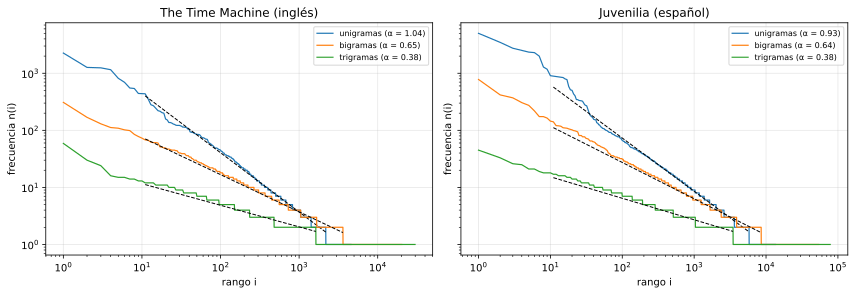

In [18]:
res_es = analizar(words_es)
res_es_ascii = analizar(words_es_ascii)
print('Juvenilia, conservando tildes y ñ')
display(tabla_ajustes(res_es).round(4))
print('Juvenilia, con Unidecode')
display(tabla_ajustes(res_es_ascii).round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
grafica_zipf(res_en, 'The Time Machine (inglés)', ax[0])
grafica_zipf(res_es, 'Juvenilia (español)', ax[1])
plt.tight_layout()
plt.show()

In [19]:
sens_es = sensibilidad(words_es)
sens_es.round(3)

R²                    α              
min_freq              1      2      3      1      2      3
n-grama   saltar                                          
bigramas  0       0.783  0.966  0.988  0.427  0.639  0.674
          10      0.780  0.965  0.987  0.424  0.636  0.673
          50      0.774  0.960  0.984  0.417  0.630  0.668
trigramas 0       0.483  0.910  0.968  0.142  0.379  0.416
          10      0.478  0.900  0.962  0.140  0.377  0.421
          50      0.466  0.877  0.940  0.134  0.366  0.420
unigramas 0       0.962  0.989  0.993  0.925  0.937  0.935
          10      0.960  0.988  0.993  0.922  0.932  0.927
          50      0.957  0.987  0.993  0.917  0.924  0.914

### Conclusiones del ejercicio 3

* *Juvenilia* es unas **2,6 veces más largo** que *The Time Machine* (84 269 palabras frente a 32 775) y tiene un vocabulario tres veces mayor (13 547 palabras distintas).
* **También cumple la ley de Zipf**: unigramas $\alpha\approx0{,}93$ ($R^2\approx0{,}99$), bigramas $\approx0{,}64$ y trigramas $\approx0{,}38$, con el mismo patrón que en inglés (exponente decreciente con $n$, ajuste peor con $n$).
* **Tildes y Unidecode apenas cambian los exponentes** (diferencias en la tercera cifra decimal), pero sí el vocabulario: al quitar tildes se fusionan 165 formas («él»/«el», «qué»/«que»…) y el alfabeto pasa de 33 a 26 letras.

## 10. Ejercicio 4 — Comparación entre idiomas

### Resumen de ambos corpus

In [20]:
def resumen(palabras, texto, res):
    letras = collections.Counter(c for c in texto if c != ' ')
    total = sum(letras.values())
    return {'palabras (tokens)': len(palabras), 'palabras distintas (tipos)': len(set(palabras)),
            'tipos / tokens': len(set(palabras)) / len(palabras),
            '% de tipos con frecuencia 1': 100 * res['unigramas']['hapax'] / res['unigramas']['tipos'],
            'longitud media de palabra': np.mean([len(w) for w in palabras]),
            'letras más frecuentes': ' '.join(c for c, _ in letras.most_common(9)),
            '% de la letra más frecuente': 100 * letras.most_common(1)[0][1] / total,
            '10 palabras más frecuentes': ' '.join(w for w, _ in collections.Counter(palabras).most_common(10)),
            'α unigramas': res['unigramas']['alpha'], 'α bigramas': res['bigramas']['alpha'],
            'α trigramas': res['trigramas']['alpha']}


comparacion = pd.DataFrame({'The Time Machine (inglés)': resumen(words, text, res_en),
                            'Juvenilia (español)': resumen(words_es, text_es, res_es)})
comparacion

,The Time Machine (inglés),Juvenilia (español)
palabras (tokens),32775,84269
palabras distintas (tipos),4579,13547
tipos / tokens,0.13971,0.160759
% de tipos con frecuencia 1,52.347674,57.156566
longitud media de palabra,4.291472,4.728809
letras más frecuentes,e t a i n o s h r,e a o s n r i l d
% de la letra más frecuente,12.682275,12.723969
10 palabras más frecuentes,the i and of a to was in that my,de la que el y en a los un su
α unigramas,1.038922,0.931818
α bigramas,0.652131,0.636281


### ¿Cuánto influye el tamaño del corpus?

Los dos corpus no tienen el mismo tamaño y el exponente estimado depende de ello (con más texto aparecen más palabras raras y la cola cambia). Para comparar en igualdad de condiciones se ajusta Zipf en **fragmentos de *Juvenilia* con el mismo número de palabras que *The Time Machine*** (32 775), tomados en tres posiciones del libro. Además, como en escala log-log la mayoría de los puntos están en la cola (de 1 000 a 2 000 hay tantos rangos como de 1 a 1 000), se repite el ajuste **promediando los puntos en 20 intervalos de igual anchura en $\log i$**, para que todas las zonas de la curva pesen lo mismo.

In [21]:
def ajustar_zipf_intervalos(freqs, saltar=10, min_freq=2, n_intervalos=20):
    """Ajuste de Zipf sobre las medias de 20 intervalos de igual anchura en log10(rango)."""
    f = np.asarray(freqs, dtype=float)
    rango = np.arange(1, len(f) + 1)
    usar = (rango > saltar) & (f >= min_freq)
    x, y = np.log10(rango[usar]), np.log10(f[usar])
    bordes = np.linspace(x.min(), x.max(), n_intervalos + 1)
    grupo = np.clip(np.digitize(x, bordes) - 1, 0, n_intervalos - 1)
    xm = np.array([x[grupo == g].mean() for g in np.unique(grupo)])
    ym = np.array([y[grupo == g].mean() for g in np.unique(grupo)])
    return -np.polyfit(xm, ym, 1)[0]


N = len(words)
fragmentos = {'The Time Machine (completo)': words,
              'Juvenilia completo': words_es,
              'Juvenilia, primeras 32 775': words_es[:N],
              'Juvenilia, central 32 775': words_es[len(words_es) // 2 - N // 2: len(words_es) // 2 + N // 2 + 1],
              'Juvenilia, últimas 32 775': words_es[-N:]}
filas = []
for nombre, pal in fragmentos.items():
    fila = {'corpus': nombre, 'palabras': len(pal), 'tipos': len(set(pal))}
    for n, et in ((1, 'uni'), (2, 'bi'), (3, 'tri')):
        freqs = frecuencias(ngramas(pal, n))
        fila[f'α {et} (MCO)'] = ajustar_zipf(freqs)['alpha']
        fila[f'α {et} (intervalos)'] = ajustar_zipf_intervalos(freqs)
    filas.append(fila)
tabla_tamano = pd.DataFrame(filas).set_index('corpus')
tabla_tamano.round(3)

,palabras,tipos,α uni (MCO),α uni (intervalos),α bi (MCO),α bi (intervalos),α tri (MCO),α tri (intervalos)
corpus,,,,,,,,
The Time Machine (completo),32775,4579,1.039,1.010,0.652,0.671,0.378,0.430
Juvenilia completo,84269,13547,0.932,0.982,0.636,0.685,0.377,0.426
"Juvenilia, primeras 32 775",32775,7545,0.858,0.964,0.574,0.621,0.300,0.369
"Juvenilia, central 32 775",32775,7298,0.868,0.959,0.583,0.642,0.304,0.352
"Juvenilia, últimas 32 775",32775,6962,0.899,0.974,0.590,0.650,0.319,0.358


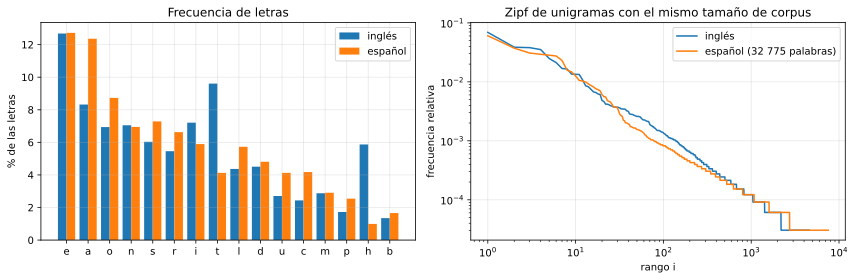

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
letras_en = collections.Counter(c for c in text if c != ' ')
letras_es = collections.Counter(c for c in text_es if c != ' ')
top = [c for c, _ in (letras_en + letras_es).most_common(16)]
pos = np.arange(len(top))
ax[0].bar(pos - 0.2, [100 * letras_en[c] / sum(letras_en.values()) for c in top], 0.4, label='inglés')
ax[0].bar(pos + 0.2, [100 * letras_es[c] / sum(letras_es.values()) for c in top], 0.4, label='español')
ax[0].set_xticks(pos, top)
ax[0].set(ylabel='% de las letras', title='Frecuencia de letras')
ax[0].legend()
for pal, nombre in ((words, 'inglés'), (words_es[:N], 'español (32 775 palabras)')):
    freqs = frecuencias(pal)
    ax[1].loglog(np.arange(1, len(freqs) + 1), np.asarray(freqs) / len(pal), label=nombre)
ax[1].set(xlabel='rango i', ylabel='frecuencia relativa', title='Zipf de unigramas con el mismo tamaño de corpus')
ax[1].legend()
plt.tight_layout()
plt.show()

### Comparación con la literatura

| | Inglés (corpus grandes) | *The Time Machine* | Español (corpus grandes) | *Juvenilia* |
|---|---|---|---|---|
| Letras más frecuentes | e t a o i n s h r | e t a i n o s h r | e a o s r n i d l | e a o s n r i l d |
| Palabras más frecuentes | the, be, to, of, and, a, in, that… (Oxford English Corpus) | the, i, and, of, a, to, was, in, that, my | de, la, que, el, en, y, a, los, se, del… (CREA, RAE) | de, la, que, el, y, en, a, los, un, su |
| Exponente de Zipf (unigramas) | ≈ 1 | 1,04 | ≈ 1 | 0,93 (0,86–0,96 según tamaño y método) |

### Conclusiones del ejercicio 4

**Caracteres.**
* En ambos idiomas la **«e» es la letra más frecuente** (≈ 12,7 % de las letras en los dos libros). Después, el inglés usa mucho la «t» (por *the*, *that*, *it*…) y el español, la «a» y la «o» (terminaciones de género: *-a*, *-o*, *-os*, *-as*). La «s» es más frecuente en español (plurales).
* Los órdenes obtenidos coinciden casi exactamente con los de corpus grandes de cada idioma: incluso un libro basta para estimar bien la frecuencia de **letras**, porque hay pocas (26–33) y cada una aparece miles de veces.
* El español necesita 7 símbolos más (á é í ó ú ü ñ). Son poco frecuentes, pero conservarlos evita confundir palabras distintas.

**Palabras.**
* En los dos idiomas mandan las *stop words*, como en los grandes corpus. En inglés aparece **«i»** en segundo lugar y **«my»** en el décimo porque *The Time Machine* está narrada en primera persona: un solo libro refleja el estilo de su autor. En español el orden (de, la, que, el, y, en…) es casi idéntico al de los corpus de referencia.
* El español tiene **más palabras distintas por cada palabra de texto** (con el mismo número de palabras, entre 6 962 y 7 545 tipos según el fragmento, frente a 4 579): su morfología es más rica (conjugaciones, género y número), así que una misma raíz aparece en muchas formas. Además, el español usa más palabras funcionales cortas (*de, la, el, en*) y combinaciones de artículo + preposición (*de la, en el*) dominan los bigramas.

**Exponentes de Zipf.**
* **Ambos corpus cumplen la ley de Zipf** y el exponente de unigramas está cerca del valor 1 de la literatura: 1,04 en inglés y 0,93 en español.
* **El exponente del español es algo menor** (cola más larga y plana), coherente con su mayor variedad de formas: la frecuencia se reparte entre más palabras. La magnitud de la diferencia **depende del método**: con el mismo número de palabras y el ajuste por mínimos cuadrados sobre todos los puntos, la diferencia incluso crece (1,04 frente a 0,86–0,90); con el ajuste por intervalos, que no da tanto peso a la cola, los dos idiomas quedan muy cerca (1,01 frente a 0,96–0,97). Por tanto, el español tiene una cola más pesada, pero la parte central de la curva sigue en ambos idiomas una ley con α ≈ 1.
* **Bigramas y trigramas** tienen exponentes casi iguales en los dos idiomas (≈ 0,64–0,65 y ≈ 0,38): la estructura de las combinaciones de palabras es similar.

**Limitaciones (corpus pequeños).**
* Con 30 000–85 000 palabras, más de la mitad del vocabulario aparece **una sola vez** (52 % y 57 %), y el 95 % de los trigramas. Las estimaciones de α en la cola son poco fiables y sensibles a los cortes del ajuste, sobre todo para trigramas.
* Un solo autor y un solo género no representan un idioma: el estilo (primera persona, temas del libro) se refleja en las palabras y en los $n$-gramas más frecuentes («the time traveller», «de la vida»).
* Comparar exponentes exige el mismo tamaño de corpus y el mismo método de ajuste; si no, parte de la diferencia es metodológica.

## 11. Ejercicio 5 — Codificaciones y perplejidad

### 11.1 One-hot

Cada token se representa con un vector del tamaño del vocabulario, con un 1 en su índice y 0 en el resto. Es la entrada típica de una RNN a nivel de carácter. Ejemplo de las diapositivas: vocabulario `{h:0, e:1, l:2, o:3}` y la palabra «hello».

In [23]:
vocab_hello = {'h': 0, 'e': 1, 'l': 2, 'o': 3}
indices_hello = torch.tensor([vocab_hello[c] for c in 'hello'])
print('índices:', indices_hello.tolist())
print(F.one_hot(indices_hello, num_classes=len(vocab_hello)))

vocab_chars = Vocab(tokens)
X = F.one_hot(torch.tensor(corpus[:10]), num_classes=len(vocab_chars))
print('\nPrimeros 10 caracteres de The Time Machine en one-hot:', tuple(X.shape))
print(f'Con palabras, cada vector tendría {len(vocab)} componentes (todas a 0 menos una)')

índices: [0, 1, 2, 2, 3]
tensor([[1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        [0, 0, 1, 0],
        [0, 0, 0, 1]])

Primeros 10 caracteres de The Time Machine en one-hot: (10, 28)
Con palabras, cada vector tendría 4580 componentes (todas a 0 menos una)


### 11.2 Bolsa de palabras (BoW)

Cuenta cuántas veces aparece cada token y **descarta el orden**. Ejemplo de las diapositivas con los caracteres de «cat in the hat»:

In [24]:
frase = 'cat in the hat'
vocab_bow = list(dict.fromkeys(frase))                   # orden de primera aparición, como en la diapositiva
bow = [frase.count(c) for c in vocab_bow]
print(dict(zip(vocab_bow, bow)))
print('¿«the in cat hat» da el mismo vector?', bow == ['the in cat hat'.count(c) for c in vocab_bow])

{'c': 1, 'a': 2, 't': 3, ' ': 3, 'i': 1, 'n': 1, 'h': 2, 'e': 1}
¿«the in cat hat» da el mismo vector? True


> La diapositiva indica que «t» aparece 2 veces, pero aparece **3** (c**a****t**, **t**he, ha**t**). El vector correcto es `[1, 2, 3, 3, 1, 1, 2, 1]` para `[c, a, t, ' ', i, n, h, e]`. Como el BoW no conserva el orden, «the in cat hat» da el mismo vector: por eso no se usa como entrada de una RNN.

### 11.3 TF-IDF

$$\text{TF}(t,d)=\frac{\text{veces que aparece }t\text{ en }d}{\text{palabras de }d},\qquad \text{IDF}(t,D)=\log_{10}\frac{\text{documentos de }D}{\text{documentos que contienen }t},\qquad \text{TF-IDF}=\text{TF}\cdot\text{IDF}.$$

Se reproduce el ejemplo de las diapositivas con dos documentos.

In [25]:
docs = ['The cat sat on the mat', 'The dog chased the cat']
docs_tok = [d.lower().split() for d in docs]
terminos = list(dict.fromkeys(t for d in docs_tok for t in d))
tf = pd.DataFrame([[d.count(t) / len(d) for t in terminos] for d in docs_tok], columns=terminos, index=['doc 1', 'doc 2'])
idf = pd.Series({t: math.log10(len(docs_tok) / sum(t in d for d in docs_tok)) for t in terminos}, name='IDF')
print('TF'); display(tf.round(3))
print('IDF'); display(idf.round(3).to_frame().T)
print('TF-IDF'); display((tf * idf).round(3))

TF


,the,cat,sat,on,mat,dog,chased
doc 1,0.333,0.167,0.167,0.167,0.167,0.0,0.0
doc 2,0.400,0.200,0.000,0.000,0.000,0.2,0.2


IDF


,the,cat,sat,on,mat,dog,chased
IDF,0.0,0.0,0.301,0.301,0.301,0.301,0.301


TF-IDF


,the,cat,sat,on,mat,dog,chased
doc 1,0.0,0.0,0.05,0.05,0.05,0.00,0.00
doc 2,0.0,0.0,0.00,0.00,0.00,0.06,0.06


«the» y «cat» aparecen en los dos documentos: IDF = log(2/2) = 0 y su TF-IDF es 0 aunque sean frecuentes. Las palabras exclusivas de cada documento reciben el peso: $\frac16\cdot\log_{10}2\approx0{,}05$ en el primero y $\frac15\cdot\log_{10}2\approx0{,}06$ en el segundo, como en las diapositivas. TF-IDF destaca lo **característico** de cada documento, pero no capta el significado ni el orden.

### 11.4 Perplejidad

$$\text{PP}(W)=P(w_1,\dots,w_n)^{-1/n}=\exp\Big(-\frac1n\sum_{t=1}^n\log P(w_t\mid w_{t-1},\dots,w_1)\Big)=\exp(\text{entropía cruzada}).$$

Es la inversa de la probabilidad normalizada (media geométrica) que el modelo asigna al texto. Vale 1 si el modelo acierta siempre con probabilidad 1 y $|V|$ si reparte la probabilidad uniformemente entre los $|V|$ tokens. Ejemplo de las diapositivas, «a red fox.»:

In [26]:
def perplejidad(probs):
    """exp(-media de log p): equivale a 1 / (producto de p)^(1/n)."""
    probs = np.asarray(probs, dtype=float)
    return float(np.exp(-np.log(probs).mean()))


p_modelo = [0.4, 0.27, 0.55, 0.79]          # P(a), P(red|a), P(fox|a red), P(.|a red fox)
P = np.prod(p_modelo)
print(f'P("a red fox.") = {P:.4f} | P normalizada = {P ** (1 / 4):.3f} | PP = {1 / P ** (1 / 4):.2f} '
      f'= {perplejidad(p_modelo):.2f}')
print(f'Modelo aleatorio con 6 palabras: PP = {perplejidad([1 / 6] * 4):.2f}')

P("a red fox.") = 0.0469 | P normalizada = 0.465 | PP = 2.15 = 2.15
Modelo aleatorio con 6 palabras: PP = 6.00


### Perplejidad de modelos de n-gramas de caracteres

Para ver la perplejidad en un caso real, se entrenan modelos de **n-gramas de caracteres** contando: la probabilidad del siguiente carácter dado los $n-1$ anteriores es su frecuencia relativa, con **suavizado de Laplace** (+1 a todos los recuentos) para no asignar probabilidad 0 a combinaciones no vistas:

$$P(c_t\mid c_{t-n+1..t-1})=\frac{\text{cuenta}(c_{t-n+1..t})+1}{\text{cuenta}(c_{t-n+1..t-1})+|V|}.$$

Se entrena con el primer 90 % de cada texto y se mide la perplejidad en el 10 % final (texto no visto). Es una versión «por conteo» de lo que hará la RNN del Lab 2.

Símbolos distintos (|V|): {'inglés': 27, 'español (tildes)': 34, 'español (Unidecode)': 27}


texto,español (Unidecode),español (tildes),inglés
n,,,
1,15.82,17.02,16.73
2,8.95,9.44,9.61
3,6.52,6.74,6.51
4,5.21,5.48,5.41
5,5.22,5.81,6.19
6,6.50,7.62,8.22


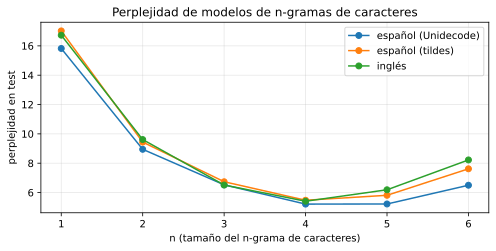

In [27]:
def perplejidad_ngramas(texto, n, frac_train=0.9):
    alfabeto = sorted(set(texto))
    corte = int(len(texto) * frac_train)
    train, test = texto[:corte], texto[corte:]
    cuentas_ngrama, cuentas_contexto = collections.Counter(), collections.Counter()
    for i in range(n - 1, len(train)):
        cuentas_ngrama[train[i - n + 1:i + 1]] += 1
        cuentas_contexto[train[i - n + 1:i]] += 1
    log_p = [math.log((cuentas_ngrama[test[i - n + 1:i + 1]] + 1) /
                      (cuentas_contexto[test[i - n + 1:i]] + len(alfabeto)))
             for i in range(n - 1, len(test))]
    return math.exp(-np.mean(log_p)), len(alfabeto)


filas = []
for nombre, txt in (('inglés', text), ('español (tildes)', text_es), ('español (Unidecode)', text_es_ascii)):
    for n in range(1, 7):
        pp, V = perplejidad_ngramas(txt, n)
        filas.append({'texto': nombre, 'n': n, 'PP': pp, '|V|': V})
tabla_pp = pd.DataFrame(filas).pivot(index='n', columns='texto', values='PP')
print('Símbolos distintos (|V|):', {f['texto']: f['|V|'] for f in filas if f['n'] == 1})
display(tabla_pp.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for col in tabla_pp.columns:
    ax.plot(tabla_pp.index, tabla_pp[col], marker='o', label=col)
ax.set(xlabel='n (tamaño del n-grama de caracteres)', ylabel='perplejidad en test',
       title='Perplejidad de modelos de n-gramas de caracteres')
ax.legend()
plt.tight_layout()
plt.show()

### Conclusiones del ejercicio 5

* **One-hot** es la forma más simple de dar tokens a una red: no supone ninguna relación entre tokens (todos los vectores están a la misma distancia) y su tamaño crece con el vocabulario (28 componentes por carácter, 4 580 por palabra).
* **BoW y TF-IDF** representan documentos completos por sus recuentos; pierden el orden, así que no sirven como entrada de modelos de secuencias, pero TF-IDF es útil para buscar y clasificar documentos.
* **Perplejidad**: el modelo de unigramas (sin contexto) ya baja de 27 (uniforme) a ≈ 17 porque las letras no son equiprobables. Con más contexto baja hasta ≈ 5,2–5,5 con 4 caracteres: el siguiente carácter está mucho más determinado. Con 5 caracteres deja de mejorar (sube en inglés y en español con tildes) y con 6 **empeora en los tres casos**: la mayoría de los contextos largos se han visto pocas veces o ninguna (la cola de Zipf otra vez) y el modelo de conteo no generaliza. Es la razón de usar redes neuronales, que comparten parámetros entre contextos parecidos.
* Inglés y español tienen perplejidades parecidas a nivel de carácter (el español con tildes tiene un alfabeto mayor, 33 letras más el espacio, pero su ortografía es muy regular).

## 12. Resumen y conclusiones generales

In [28]:
import json

curvas = {}
for clave, res in (('en', res_en), ('es', res_es)):
    for nombre, v in res.items():
        f = np.asarray(v['freqs'])
        idx = np.unique(np.round(np.logspace(0, np.log10(len(f)), 70)).astype(int)) - 1
        curvas[f'{clave}_{nombre}'] = {'rango': (idx + 1).tolist(), 'freq': f[idx].tolist(),
                                      'alpha': float(v['alpha']), 'c': float(v['c']), 'R2': float(v['R2']),
                                      'MSE': float(v['MSE']), 'rango_min': v['rango_min'], 'rango_max': v['rango_max'],
                                      'tipos': v['tipos'], 'hapax': v['hapax']}
resumen_json = {
    'curvas': curvas,
    'tamano': tabla_tamano.reset_index().to_dict(orient='records'),
    'comparacion': {k: {i: (float(x) if isinstance(x, (int, float, np.floating, np.integer)) else x)
                        for i, x in col.items()} for k, col in comparacion.to_dict().items()},
    'pp': {col: {int(n): float(v) for n, v in tabla_pp[col].items()} for col in tabla_pp.columns},
    'letras': {'en': {c: 100 * letras_en[c] / sum(letras_en.values()) for c in top},
               'es': {c: 100 * letras_es[c] / sum(letras_es.values()) for c in top}},
}
with open(LAB_DIR / 'resultados_lab1.json', 'w', encoding='utf-8') as f:
    json.dump(resumen_json, f, ensure_ascii=False, indent=1)
print('Resultados guardados en resultados_lab1.json')

Resultados guardados en resultados_lab1.json


* El texto se convierte en secuencias con un flujo fijo: **cargar → preprocesar → tokenizar → vocabulario → índices**. Qué es un token (carácter, palabra o subpalabra) es una decisión de diseño con consecuencias: tamaño del vocabulario, longitud de las secuencias y palabras desconocidas.
* El preprocesado depende del idioma: el regex del inglés destruye las palabras españolas con tilde o ñ.
* **La ley de Zipf se cumple** en los dos idiomas: α ≈ 1 para palabras (1,04 en inglés, 0,93 en español) y exponentes menores para bigramas (≈ 0,65) y trigramas (≈ 0,38). El español muestra más palabras distintas y una cola algo más plana, aunque parte de la diferencia se debe al tamaño del corpus y al método de ajuste.
* La mayoría de las palabras y casi todos los trigramas son raros: los modelos basados en contar no generalizan (la perplejidad de los n-gramas de caracteres deja de mejorar con 5 caracteres y empeora con 6). Los modelos neuronales (RNN en el Lab 2) resuelven esto compartiendo parámetros.
* La **perplejidad** = exp(entropía cruzada) mide la «incertidumbre efectiva» del modelo: entre 1 (certeza) y |V| (azar).